In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kubernetes_logs_13300_with_errors.csv to kubernetes_logs_13300_with_errors.csv


In [ ]:

import pandas as pd

df = pd.read_csv(
    "kubernetes_logs_13300_with_errors.csv",
    header=None,
    names=["event", "method", "path", "status"]
)

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

display(df.head(10))


Dataset shape: (13300, 4)

Missing values:
event     0
method    0
path      0
status    0
dtype: int64


,event,method,path,status
0,RESOURCE_EXHAUSTED,POST,/create-room/,503
1,PASSWORDRESET_ACCESSED,GET,/password_reset/,200
2,LOGIN_ACCESSED,GET,/login/,200
3,REGISTER_ACCESSED,GET,/register/,200
4,INVALID_REQUEST,POST,/login/,401
5,LOGIN_ACCESSED,GET,/login/,200
6,HOME_ACCESSED,GET,/,200
7,HOME_ACCESSED,GET,/,200
8,LOGIN_SUCCESS,POST,/login/,302
9,INVALID_REQUEST,POST,/login/,401


In [ ]:

# Convert status to a number
df["status"] = pd.to_numeric(df["status"])

# Label server errors
df["label"] = (df["status"] >= 500).astype(int)

print(df["label"].value_counts())


label
0    12008
1     1292
Name: count, dtype: int64


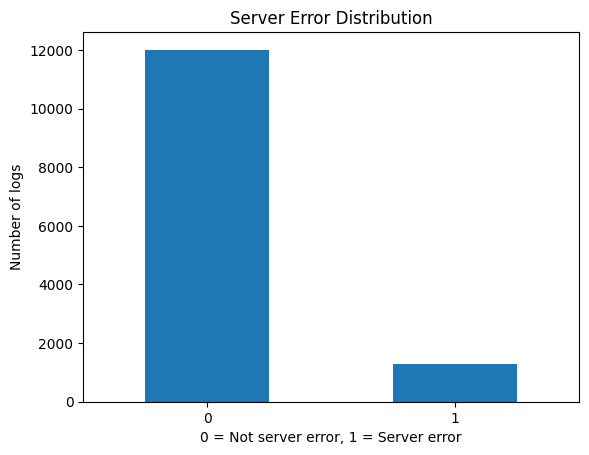

In [ ]:

import matplotlib.pyplot as plt

counts = df["label"].value_counts().sort_index()

counts.plot(kind="bar")
plt.title("Server Error Distribution")
plt.xlabel("0 = Not server error, 1 = Server error")
plt.ylabel("Number of logs")
plt.xticks(rotation=0)
plt.show()


In [ ]:

df["log_text"] = (
    df["event"].astype(str) + " " +
    df["method"].astype(str) + " " +
    df["path"].astype(str)
)

X = df["log_text"]
y = df["label"]

display(df[["log_text", "label"]].head())


,log_text,label
0,RESOURCE_EXHAUSTED POST /create-room/,1
1,PASSWORDRESET_ACCESSED GET /password_reset/,0
2,LOGIN_ACCESSED GET /login/,0
3,REGISTER_ACCESSED GET /register/,0
4,INVALID_REQUEST POST /login/,0


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 10640
Testing samples: 2660


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        token_pattern=r"(?u)\b\w+\b"
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("Model training completed!")


Model training completed!


Accuracy: 1.0

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2402
           1       1.00      1.00      1.00       258

    accuracy                           1.00      2660
   macro avg       1.00      1.00      1.00      2660
weighted avg       1.00      1.00      1.00      2660



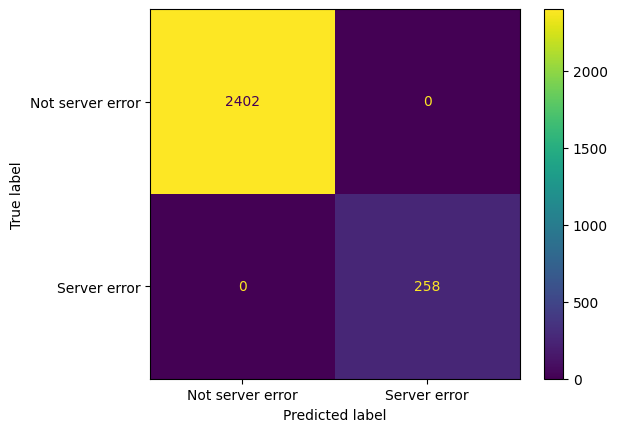

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not server error", "Server error"]
)
plt.show()


In [ ]:

new_logs = [
    "LOGIN_ACCESSED GET /login/",
    "RESOURCE_EXHAUSTED POST /create-room/",
    "ROOM_SUCCESS GET /room/"
]

predictions = model.predict(new_logs)
probabilities = model.predict_proba(new_logs)

for log, prediction, probability in zip(
    new_logs, predictions, probabilities
):
    print("Log:", log)
    print("Predicted class:", prediction)
    print("Server-error class probability:",
          round(probability[1], 3))
    print("---")


Log: LOGIN_ACCESSED GET /login/
Predicted class: 0
Server-error class probability: 0.0
---
Log: RESOURCE_EXHAUSTED POST /create-room/
Predicted class: 1
Server-error class probability: 1.0
---
Log: ROOM_SUCCESS GET /room/
Predicted class: 0
Server-error class probability: 0.07
---


In [ ]:

import joblib
from google.colab import files

joblib.dump(model, "random_forest_log_classifier.pkl")

files.download("random_forest_log_classifier.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Count repeated log messages
print("Total records:", len(df))
print("Unique log messages:", df["log_text"].nunique())

# Check overlap between training and testing
train_logs = set(X_train)
test_logs = set(X_test)

overlap = train_logs.intersection(test_logs)

print("Shared unique log messages:", len(overlap))
print("Total unique test messages:", len(test_logs))

print("\nExample overlapping messages:")
print(list(overlap)[:10])


Total records: 13300
Unique log messages: 89
Shared unique log messages: 78
Total unique test messages: 79

Example overlapping messages:
['CREATEROOM_ACCESSED GET /create-room/', 'NOT_FOUND GET /<invalid-route>', 'AUTH_REDIRECT GET /delete-message/<id>/', 'LOGOUT_SUCCESS GET /logout/', 'PROFILEUPDATE_FAILED GET /profile/<username>/update/', 'DATABASE_CONNECTION_ERROR GET /room/<id>/', 'DELETEROOM_FAILED GET /delete-room/<id>/', 'UPDATEROOM_ACCESSED GET /update-room/<id>/', 'ROOM_ACCESSED GET /room/<id>/', 'RATE_LIMIT_EXCEEDED POST /login/']


In [ ]:

conflicts = df.groupby("log_text")["label"].nunique()

print("Total unique log patterns:", len(conflicts))
print("Patterns with conflicting labels:",
      (conflicts > 1).sum())

print("Patterns with consistent labels:",
      (conflicts == 1).sum())


Total unique log patterns: 89
Patterns with conflicting labels: 0
Patterns with consistent labels: 89


Shared patterns: 0
Training records: 9351
Testing records: 3949

Accuracy: 0.9182071410483666

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96      3628
           1       0.46      0.04      0.07       321

    accuracy                           0.92      3949
   macro avg       0.69      0.52      0.51      3949
weighted avg       0.88      0.92      0.89      3949



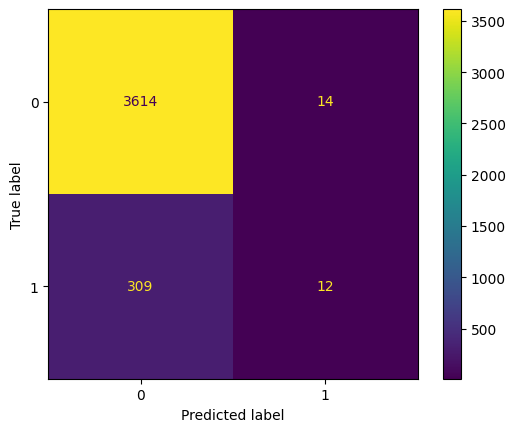

In [ ]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        df["log_text"],
        df["label"],
        groups=df["log_text"]
    )
)

X_train_new = df["log_text"].iloc[train_idx]
X_test_new = df["log_text"].iloc[test_idx]

y_train_new = df["label"].iloc[train_idx]
y_test_new = df["label"].iloc[test_idx]

# Verify there is no overlap
overlap = set(X_train_new) & set(X_test_new)

print("Shared patterns:", len(overlap))
print("Training records:", len(X_train_new))
print("Testing records:", len(X_test_new))

# Train a new model
new_model = clone(model)
new_model.fit(X_train_new, y_train_new)

# Evaluate
predictions = new_model.predict(X_test_new)

print("\nAccuracy:",
      accuracy_score(y_test_new, predictions))

print("\nClassification Report:")
print(classification_report(
    y_test_new,
    predictions,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_new,
    predictions
)

plt.show()


In [ ]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Use the model trained on unseen log patterns
probabilities = new_model.predict_proba(X_test_new)[:, 1]

results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    predictions = (probabilities >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test_new, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_new, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test_new, predictions, zero_division=0
        )
    })

display(pd.DataFrame(results))


,Threshold,Precision,Recall,F1
0,0.1,0.177215,0.348910,0.235047
1,0.2,0.065574,0.037383,0.047619
2,0.3,0.065574,0.037383,0.047619
3,0.4,0.461538,0.037383,0.069164
4,0.5,0.461538,0.037383,0.069164


In [ ]:

!pip install -q xgboost


In [ ]:

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

xgb_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        token_pattern=r"(?u)\b\w+\b"
    )),
    ("classifier", XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_model.fit(X_train_new, y_train_new)

print("XGBoost training completed!")


XGBoost training completed!


XGBoost Accuracy: 86.76 %

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.94      0.93      3628
           1       0.05      0.04      0.04       321

    accuracy                           0.87      3949
   macro avg       0.49      0.49      0.49      3949
weighted avg       0.85      0.87      0.86      3949



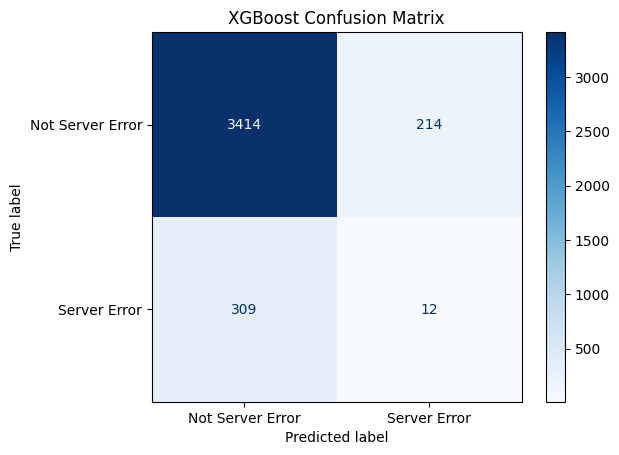

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Make predictions
xgb_predictions = xgb_model.predict(X_test_new)

# Calculate accuracy
accuracy = accuracy_score(y_test_new, xgb_predictions)

print("XGBoost Accuracy:", round(accuracy * 100, 2), "%")

# Detailed evaluation
print("\nClassification Report:")
print(classification_report(
    y_test_new,
    xgb_predictions,
    zero_division=0
))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_new,
    xgb_predictions,
    display_labels=["Not Server Error", "Server Error"],
    cmap="Blues"
)

plt.title("XGBoost Confusion Matrix")
plt.show()
